# Function 8 - Week 6: Observation review

Review of measured outputs and full input profiles through the **Week 5 return, received on 30 October 2026 at 14:57 GMT**.

The independent official snapshot contains **40 initial observations and five returned queries (45 rows)**. All 8 input settings lie in `[0, 1)`. Larger signed outputs are better. Earlier snapshots and separate cohort analyses retain their historical evidence.

The latest output is **9.21830008**, **rank 5/45 (1 = highest output)**. It does not improve the prior incumbent of **9.59848200257**. Original inputs and outputs remain at full precision in the local CSV and structured result record.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
FUNCTION_NUMBER = 8
CURRENT_WEEK = 6
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 40, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"


In [3]:
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
prepared = prepare_weekly_observation_review(review)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y,output_rank
44,round-05,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.999999,9.2183,5


Latest recorded submission: round 5 (1 new output).
Compared with 44 earlier observations (45 outputs in total).
Earlier output range: [5.59219338954, 9.59848200257].

round-05: y = 9.21830008 (positive); rank 5/45 (1 = highest output).
Inputs: x1 = 0, x2 = 0, x3 = 0, x4 = 0, x5 = 0, x6 = 0, x7 = 0, x8 = 0.999999
Within the earlier output range.


### Measured outputs

Both panels use signed outputs in their original units. The close-up shows only the highest five; all observations remain in the full-range panel and calculations.

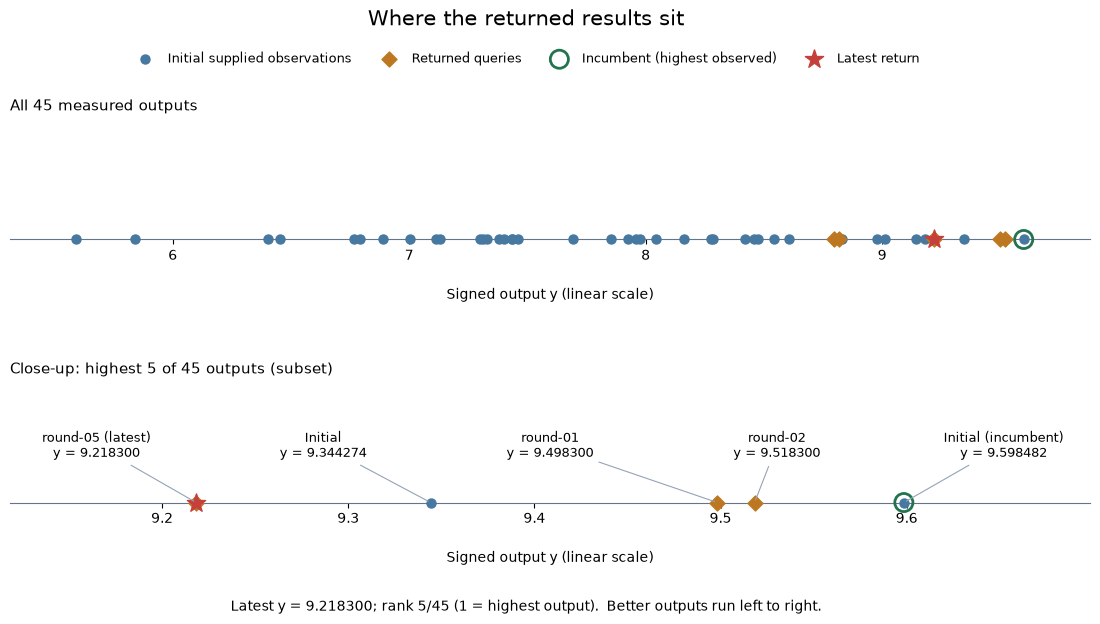

In [4]:
plot_output_review(review, save_to=FIGURES_DIR / "observed-output-review.png")

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [5]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,9.598482,Not applicable
Round 1,9.498300,9.598482,-0.100182
Round 2,9.518300,9.598482,-0.080182
Round 3,8.798303,9.598482,-0.800179
Round 4,8.818303,9.598482,-0.780179
Round 5,9.218300,9.598482,-0.380182


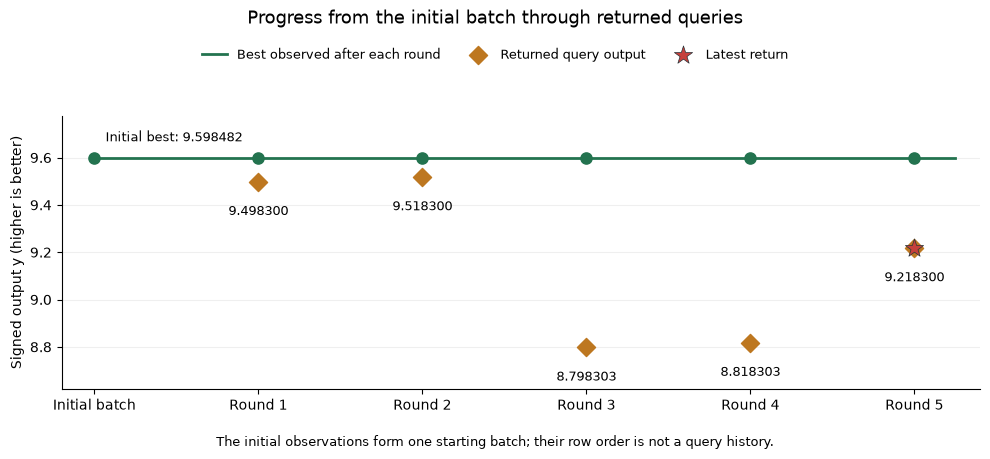

In [6]:
plot_round_progress(prepared["progress"], save_to=FIGURES_DIR / "observed-progress.png")

### Strongest measured input combinations

Keep all 8 coordinates visible. Colour shows input settings on a common 0–1 scale; it does not encode performance or input effects. Use the table for six-decimal settings.

,rank,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y
observation_id,,,,,,,,,,,
initial-015,1,0,0.056447,0.065956,0.022929,0.038786,0.403935,0.801055,0.488307,0.893085,9.598482
round-02,2,2,0.000000,0.000000,0.000000,0.000000,0.999999,0.000000,0.000000,0.999999,9.518300
round-01,3,1,0.000000,0.000000,0.000000,0.000000,0.999999,0.000000,0.000000,0.000000,9.498300
initial-027,4,0,0.192640,0.630677,0.416796,0.490529,0.796086,0.654567,0.276241,0.295518,9.344274
round-05,5,5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.999999,9.218300


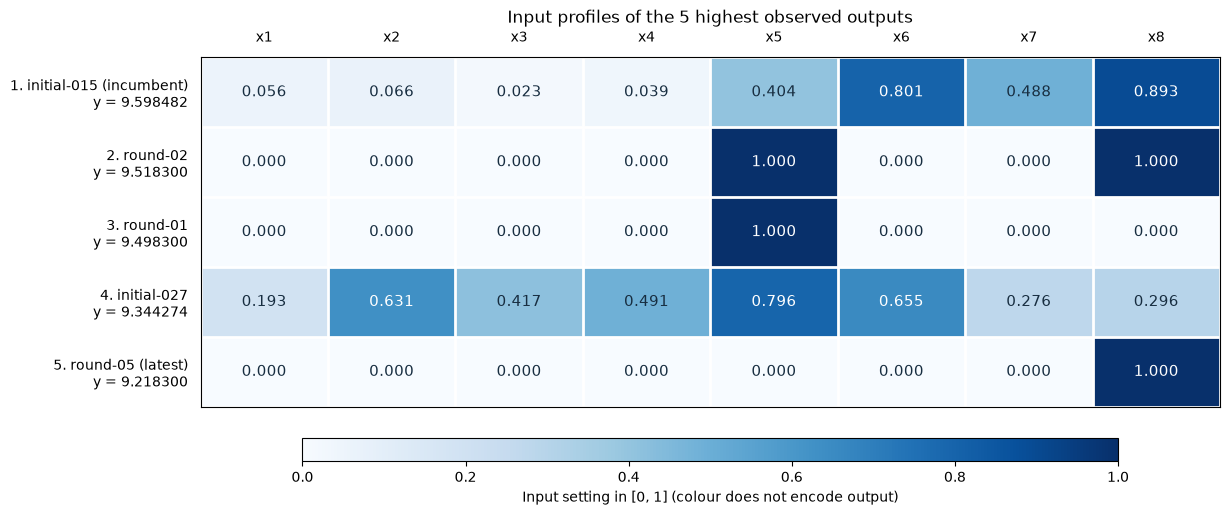

In [7]:
display(prepared["strongest"][["rank", "observation_id", "source_round", *INPUT_COLUMNS, OUTPUT_COLUMN]]
    .set_index("observation_id").style.format({column: "{:.6f}" for column in [*INPUT_COLUMNS, OUTPUT_COLUMN]}))
plot_input_profiles(
    prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=prepared["latest"]["observation_id"], incumbent_id=prepared["incumbent"]["observation_id"],
    save_to=FIGURES_DIR / "strongest-input-profiles.png",
)


### Latest input versus earlier evidence

Distances use every input coordinate. Similar input settings do not guarantee similar outputs or isolate the effect of one coordinate.

In [8]:
display(prepared["coordinate_changes"].style.format(precision=6))
display(pd.Series(prepared["neighbour_summary"]))


,Previous best,Latest query,Latest minus previous best
x1,0.056447,0.000000,-0.056447
x2,0.065956,0.000000,-0.065956
x3,0.022929,0.000000,-0.022929
x4,0.038786,0.000000,-0.038786
x5,0.403935,0.000000,-0.403935
x6,0.801055,0.000000,-0.801055
x7,0.488307,0.000000,-0.488307
x8,0.893085,0.999999,0.106914


previous_best_id              initial-015
previous_best_output             9.598482
distance_to_previous_best        1.031646
latest_minus_previous_best      -0.380182
nearest_previous_id           initial-040
nearest_previous_distance        0.988693
dtype: object

### Saved Week 5 forecast at the submitted input

Read the preserved submission selection record without refitting. Posterior SD is model dependent; one forecast error does not establish calibration. UCB is a selection score, not a measured return.

In [9]:
# Read the saved selection record at the actual submitted input; no model is refitted.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_05/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "6ca900244a2c11ab030075a37c7aae25ef8362651db03ddbc78b7b324cd5bcca":
    raise ValueError("The historical Week 5 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
historical_forecast = dict(selection.get("model_prediction") or {})
historical_forecast["data_scope"] = selection["data_scope"]
historical_forecast["actual_output"] = float(prepared["latest"][OUTPUT_COLUMN])
if "predicted_output" in historical_forecast:
    historical_forecast["actual_minus_prediction"] = (
        historical_forecast["actual_output"] - historical_forecast["predicted_output"])
else:
    historical_forecast["forecast_status"] = "Not applicable: fixed coverage selection"
display(pd.Series(historical_forecast))


predicted_output                9.432307
posterior_std                   0.588048
ucb_weight                          1.96
inside_sampled_hull                False
ucb                            10.584882
data_scope                 official_only
actual_output                     9.2183
actual_minus_prediction        -0.214007
dtype: object

### What the return adds

The unmeasured corner returned below both the initial incumbent and its saved model mean. Relative to the round 1 input it turns x5 from 0.999999 to 0 while turning x8 from 0 to 0.999999, so that comparison changes two coordinates. The five corner evaluations do not isolate general input effects or establish the optimum of the eight-dimensional function.

In [10]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(observation_summary, indent=2))


{
  "function": 8,
  "week": 6,
  "observations": 45,
  "latest_id": "round-05",
  "latest_output": 9.2183000799999,
  "latest_rank": 5,
  "rank_definition": "1 = highest output",
  "best_id": "initial-015",
  "best_observed_output": 9.598482002566342,
  "positive_outputs": 45,
  "negative_outputs": 0,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": 9.598482002566342,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": 9.4983001999995,
      "best_y": 9.598482002566342,
      "change_vs_prior_best": -0.10018180256684239
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": 9.5183002799994,
      "best_y": 9.598482002566342,
      "change_vs_prior_best": -0.08018172256694278
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "returned_y": 8.7983028999975,
  

### Course lifecycle for this review

1. **Define the goal and scope** — review round 5 for the project owner and prepare evidence for the Week 6 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 30 October results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 6 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Eight query opportunities remain, including Week 6; this notebook submits no query.
